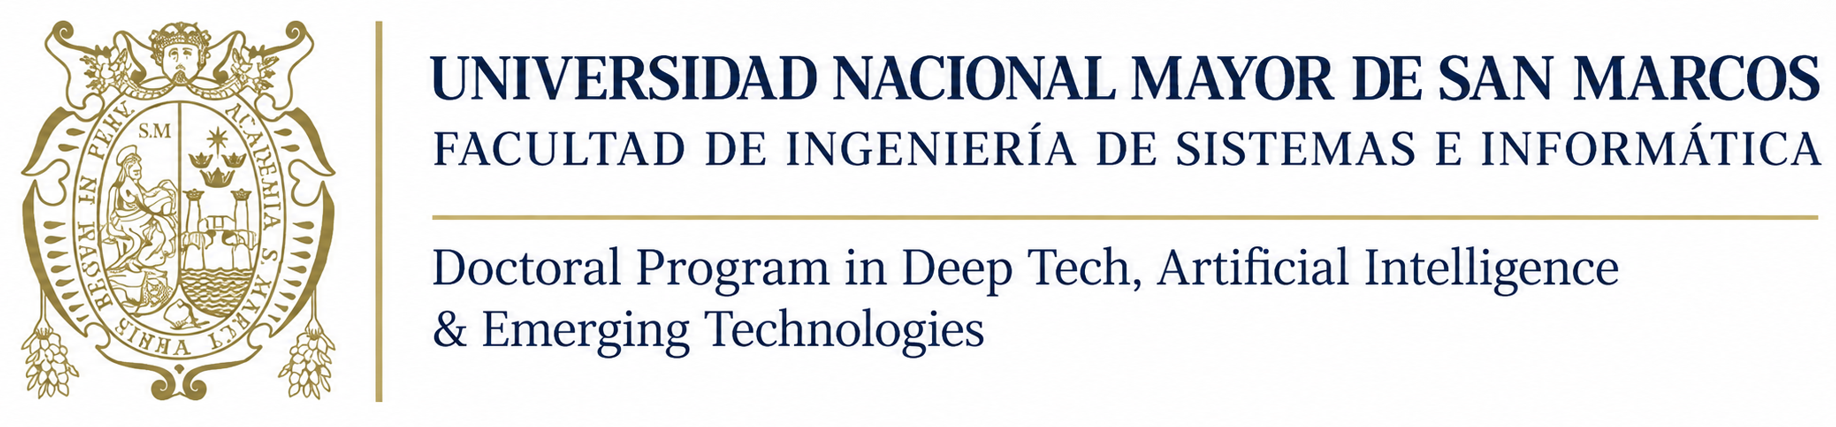



---



# **Doctoral Program in Deep Tech, Artificial Intelligence & Emerging Technologies**  

## **Course:** Research Methods and Scientific Integrity in AI and Advanced Technologies

## **Instructor:** Dr. Loveleen Gaur  

## **Student:** Miguel Ángel Patiño Antonioli [Student Code: 26207283]

## **Term**: 2026-II



---


# **Deliverable 7: MODEL CARD & DATASET DATASHEET [Human-in-the-Loop Multimodal AAC Prototype in Spanish]**



---



# Session 7: Benchmarking, Ablation Studies & Reporting Standards

Exercises 1–3 and 7–10 retain the Wisconsin Breast Cancer dataset as **course demonstrations only**.

Exercises 4–6 and 11–12 are customized to the doctoral AAC research. No classroom benchmark result is a thesis result.


## 0 · Setup


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# A real, small, fast tabular benchmark: Wisconsin Breast Cancer (569 samples, 30 features).
data = load_breast_cancer()
X, y = data.data, data.target
feature_names = list(data.feature_names)
print(f"Dataset: {data.DESCR.splitlines()[0]}")
print(f"Samples: {X.shape[0]} | Features: {X.shape[1]} | Classes: {np.bincount(y)} (0=malignant, 1=benign)")

# Honest split: train / test, stratified so class balance is preserved (Session 6 idea).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]}  Test: {X_test.shape[0]}")

## Exercise 1 · The weak-baseline illusion
**The hook, in code.** Dacrema et al. (2019) found that 6 of 7 reproducible neural recommenders were beaten by *simple, well-tuned* heuristics. The villain was rarely the fancy model — it was the **lazy baseline**.

Here we play both roles:
- a **"fancy" model** (gradient boosting) that we tune a little, and
- a **logistic-regression baseline** that we first leave *untuned*, then tune *as hard as the fancy model*.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 1 · La ilusión de la línea base débil
**El gancho, en código.** Dacrema et al. (2019) hallaron que 6 de 7 recomendadores neuronales reproducibles eran superados por heurísticas *simples y bien ajustadas*. El villano rara vez era el modelo sofisticado: era la **línea base perezosa**.

Aquí jugamos ambos papeles:
- un **modelo "sofisticado"** (gradient boosting) que ajustamos un poco, y
- una **línea base de regresión logística** que primero dejamos *sin ajustar* y luego ajustamos *con el mismo esfuerzo* que el modelo sofisticado.

Se observa cómo la "mejora" se encoge, o desaparece, cuando la línea base recibe un trato justo.

</details>

In [ ]:
# --- The "fancy" model, lightly tuned ---
fancy = make_pipeline(StandardScaler(),
                      GradientBoostingClassifier(n_estimators=200, learning_rate=0.1,
                                                 max_depth=3, random_state=RANDOM_STATE))
fancy.fit(X_train, y_train)
acc_fancy = accuracy_score(y_test, fancy.predict(X_test))

# --- Baseline #1: untuned logistic regression (the straw man) ---
weak = make_pipeline(StandardScaler(),
                     LogisticRegression(C=0.001, max_iter=2000, random_state=RANDOM_STATE))
weak.fit(X_train, y_train)
acc_weak = accuracy_score(y_test, weak.predict(X_test))

print(f"Fancy model (gradient boosting)        : {acc_fancy:.4f}")
print(f"UNTUNED baseline (logistic, C=0.001)   : {acc_weak:.4f}")
print(f"Apparent improvement over weak baseline: {acc_fancy - acc_weak:+.4f}  <-- looks impressive!")

In [ ]:
# --- Baseline #2: now tune the baseline AS HARD as we'd tune our own model ---
param_grid = {"logisticregression__C": np.logspace(-3, 2, 12)}
strong = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    param_grid, cv=5, scoring="accuracy", n_jobs=-1)
strong.fit(X_train, y_train)
acc_strong = accuracy_score(y_test, strong.predict(X_test))

print(f"Fancy model                            : {acc_fancy:.4f}")
print(f"TUNED baseline (best C={strong.best_params_['logisticregression__C']:.4g}) : {acc_strong:.4f}")
print(f"HONEST improvement over tuned baseline : {acc_fancy - acc_strong:+.4f}")
print()
print("Discuss: how much of the original 'improvement' survived a fair comparison?")

**🧪 Analysis.** The first comparison flattered the fancy model because the baseline was crippled (`C=0.001` heavily under-regularised it). The fairness test from the slides: *if a reviewer tuned your baseline with the same care you gave your model, would your gain survive?*

> The lesson is **not** "boosting is bad." It is: a comparison is only a comparison when both sides got equal effort, equal data, equal compute.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Análisis.** La primera comparación favoreció al modelo sofisticado porque la línea base estaba lisiada (`C=0.001` la regularizaba en exceso). La prueba de justicia de las diapositivas: *si un revisor ajustara tu línea base con el mismo cuidado que diste a tu modelo, ¿sobreviviría tu mejora?*

> La lección **no** es "el boosting es malo". Es: una comparación solo es una comparación cuando ambos lados recibieron el mismo esfuerzo, los mismos datos y el mismo cómputo.

</details>

## Exercise 2 · One seed is not a result
A single training run reports a single number. But stochastic training (initialisation, data order, sampling) means that number is **a draw from a distribution**. Reporting one draw is how a paper claims "89.7% beats 89.2%" when the real difference is noise (the Session 6 story).

We run the fancy model over **10 seeds** and look at the spread.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 2 · Una semilla no es un resultado
Una sola corrida de entrenamiento reporta un solo número. Pero el entrenamiento estocástico (inicialización, orden de los datos, muestreo) hace que ese número sea **una extracción de una distribución**. Reportar una sola extracción es como un artículo afirma que "89.7% supera a 89.2%" cuando la diferencia real es ruido (la historia de la Sesión 6).

Corremos el modelo sofisticado con **10 semillas** y miramos la dispersión.

</details>

In [ ]:
seeds = range(10)
accs = []
for s in seeds:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=s)
    m = make_pipeline(StandardScaler(),
                      GradientBoostingClassifier(n_estimators=200, learning_rate=0.1,
                                                 max_depth=3, random_state=s))
    m.fit(Xtr, ytr)
    accs.append(accuracy_score(yte, m.predict(Xte)))

accs = np.array(accs)
print("Per-seed accuracies:", np.round(accs, 4))
print(f"\nMean ± std : {accs.mean():.4f} ± {accs.std():.4f}")
print(f"Min / Max  : {accs.min():.4f} / {accs.max():.4f}   (spread = {accs.max()-accs.min():.4f})")
print(f"\nIf you reported only the BEST seed you'd claim {accs.max():.4f}.")
print(f"If you reported only the WORST seed you'd claim {accs.min():.4f}.")
print("Same model, same data, same code. The only thing that changed was the seed.")

In [ ]:
plt.figure()
plt.axhspan(accs.mean()-accs.std(), accs.mean()+accs.std(), color="#0E7C86", alpha=0.15, label="mean ± 1 std")
plt.axhline(accs.mean(), color="#0E7C86", lw=2, label=f"mean = {accs.mean():.3f}")
plt.scatter(list(seeds), accs, color="#16344E", zorder=5, label="per-seed accuracy")
plt.xlabel("random seed"); plt.ylabel("test accuracy")
plt.title("The variance a single-run claim would hide")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

**🧪 Analysis.** Best practice (NeurIPS / ICML reproducibility checklists): report **mean ± std over ≥5 seeds**, and ideally a statistical test before claiming one method beats another. A "+0.3%" gain inside a ±0.8% band is not a finding.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Análisis.** La buena práctica (listas de verificación de reproducibilidad de NeurIPS / ICML): reporta **media ± desv. est. sobre ≥5 semillas** e, idealmente, una prueba estadística antes de afirmar que un método supera a otro. Una "mejora" de +0.3% dentro de una banda de ±0.8% no es un hallazgo.

</details>

## Exercise 3 · A proper ablation study
An ablation removes **one component at a time** to attribute the gain. Here the "components" are groups of input features, plus the scaling step. We turn each off, keep everything else fixed, and measure the drop — reporting **mean ± std over seeds**, never a single run.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 3 · Un estudio de ablación como corresponde
Una ablación quita **un componente a la vez** para atribuir la mejora. Aquí los "componentes" son grupos de variables de entrada, más el paso de escalado. Apagamos cada uno, mantenemos todo lo demás fijo y medimos la caída, reportando **media ± desv. est. sobre semillas**, nunca una sola corrida.

</details>

In [ ]:
# Group the 30 features into the 3 blocks the dataset is built from.
def feature_block(prefix):
    return [i for i, n in enumerate(feature_names) if n.startswith(prefix)]
blocks = {
    "mean features":    feature_block("mean"),
    "error features":   feature_block("radius error") + [i for i,n in enumerate(feature_names) if "error" in n],
    "worst features":   feature_block("worst"),
}
# de-duplicate the 'error' block
blocks["error features"] = sorted(set(blocks["error features"]))

def evaluate(use_idx, scale=True, seeds=range(5)):
    scores = []
    for s in seeds:
        Xtr, Xte, ytr, yte = train_test_split(X[:, use_idx], y, test_size=0.25,
                                              stratify=y, random_state=s)
        steps = [StandardScaler()] if scale else []
        steps.append(GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=s))
        m = make_pipeline(*steps); m.fit(Xtr, ytr)
        scores.append(accuracy_score(yte, m.predict(Xte)))
    return np.mean(scores), np.std(scores)

all_idx = list(range(X.shape[1]))
rows = []
full_mean, full_std = evaluate(all_idx)
rows.append(("FULL model (all features + scaling)", full_mean, full_std, 0.0))

for name, idx in blocks.items():
    keep = [i for i in all_idx if i not in idx]
    m_, s_ = evaluate(keep)
    rows.append((f"– remove {name}", m_, s_, m_ - full_mean))

m_, s_ = evaluate(all_idx, scale=False)
rows.append(("– remove feature scaling", m_, s_, m_ - full_mean))

abl = pd.DataFrame(rows, columns=["Configuration", "Accuracy (mean)", "Std", "Δ vs full"])
abl[["Accuracy (mean)", "Std", "Δ vs full"]] = abl[["Accuracy (mean)", "Std", "Δ vs full"]].round(4)
abl

**🧪 Interpretation.** The components with the **most negative Δ** are doing the most work; a near-zero Δ means a component barely earns its place — and saying so is an honest **negative result**, exactly the kind the literature under-reports.

**🛠 Sensitivity analysis.** Change `seeds=range(5)` to `range(10)` in `evaluate`, or regroup the feature blocks, and see whether the conclusions are stable. Stability across seeds is what makes an ablation trustworthy.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Interpretación.** Los componentes con el **Δ más negativo** son los que más trabajan; un Δ cercano a cero significa que un componente apenas se justifica, y decirlo es un **resultado negativo** honesto, exactamente el tipo que la literatura subreporta.

**🛠 Análisis de Sensibilidad.** Cambia `seeds=range(5)` por `range(10)` en `evaluate`, o reagrupa los bloques de variables, y verifica si tus conclusiones se mantienen. La estabilidad entre semillas es lo que hace confiable una ablación.

</details>

## Exercise 4 · Generate a Model Card
A **Model Card** (Mitchell et al., 2019) is a short document that travels with a trained model. The nine sections are below. We fill the dictionary **honestly** and where we don't know, we write `"UNKNOWN — to investigate"` rather than leaving it blank. The gaps are the point.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 4 · Genera una Model Card
Una **Model Card** (Mitchell et al., 2019) es un documento breve que viaja con el modelo entrenado. Las nueve secciones están abajo. Llena el diccionario **con honestidad**: donde no sepas, escribe `"UNKNOWN — to investigate"` en lugar de dejarlo vacío. Las brechas son el punto.

</details>

In [ ]:
# 🛠 CUSTOMIZED FOR THE DOCTORAL RESEARCH — no invented empirical results.
model_card = {'Model details': {'Name / version': 'HITL Multimodal AAC-ES v0.0 — research specification', 'Owner / contact': 'Miguel Ángel Patiño Antonioli — UNMSM Doctoral Program in Deep Tech, AI & Emerging Technologies', 'Documentation date': '18 October 2026', 'Development status': 'Research-stage prototype specification; not yet trained, clinically validated, or deployed.', 'Architecture': 'Planned multimodal AAC artifact integrating photographs/pictograms, text, synthesized speech, contextual information, interaction history, adaptive suggestion/ranking, and human-in-the-loop review. The child retains final control to select, reject, modify, ignore, or stop.', 'License': 'UNKNOWN — to investigate before any public release.'}, 'Intended use': {'Primary intended uses': 'Research prototype to support independent functional communication in Spanish for a bounded subgroup of minimally speaking or nonspeaking autistic children requiring very substantial support, within one structured therapeutic communication context.', 'Intended users': 'Research participants supported by caregivers and qualified professionals; researchers evaluating the artifact under an approved protocol.', 'Out-of-scope / misuse': 'NOT for autism diagnosis, clinical or medical recommendations, inference of thoughts or internal states, autonomous communication on behalf of the child, unsupervised deployment, or replacement of AAC/clinical professionals.'}, 'Factors': {'Relevant groups / conditions': 'Communication profile; functional communication repertoire; sensory/contextual needs; Spanish-language and Peruvian sociocultural context; activity/context; caregiver/specialist configuration; individual interaction history.', 'Evaluation factors': 'Planned disaggregation by participant and experimental condition (intelligent prototype vs predefined static AAC comparator). Where feasible, results will also be examined by communicative function and prompting level.'}, 'Metrics': {'Primary outcome 1': 'Independent functional communication acts per session.', 'Primary outcome 2': 'Communicative diversity — range of communicative functions or concepts expressed.', 'Primary outcome 3': 'Assistance / prompting level required to communicate.', 'Secondary / process measures': 'Message-selection time; rejected or modified AI suggestions; treatment fidelity; inter-observer agreement; focused caregiver/specialist feedback.', 'Variation approach': 'Repeated within-participant comparisons across sessions. Report participant-level trajectories and condition-wise summaries. For stochastic ML benchmarking, use mean ± std over at least 5 seeds, confidence intervals, and paired comparisons when appropriate.'}, 'Evaluation data': {'Dataset / design': 'NOT YET COLLECTED. Planned pilot evaluation: minimum four participants from one clearly defined subgroup; one structured therapeutic communication context; alternating-treatments single-case design comparing the intelligent prototype with a predefined static AAC condition.', 'Evaluation protocol': 'Conditions counterbalanced or randomized where feasible; repeated measurement across sessions; prespecified session procedures, prompting hierarchy, fidelity checklist, safety/stopping rules, coding rules, and analysis logic.', 'Preprocessing': 'Planned pseudonymization and session-level coding; identifiers stored separately; a prespecified subset independently double-coded. Exact preprocessing pipeline is UNKNOWN — to investigate and freeze before data collection.'}, 'Training data': {'Datasets': 'No thesis participant data have been collected or used for model training as of this deliverable. The final foundation model/provider and any fine-tuning or adaptation data are UNKNOWN — to investigate and document before implementation.', 'Personalization data': 'If used, personalization will rely only on authorized, minimized interaction history and configured preferences; it must not silently convert test/evaluation interactions into training data.', 'Known limitations': 'No final training corpus, model checkpoint, data license, or multilingual/cultural coverage assessment is yet available.'}, 'Quantitative analyses': {'Overall results': 'NO THESIS RESULTS YET — no participant-level or model-performance claims are made in Deliverable 7.', 'Disaggregated results': 'Planned disaggregated reporting: per-participant and per-condition trajectories, with prompting/assistance explicitly separated. Aggregate summaries will not replace individual trajectories.', 'Statistical interpretation': 'Quantitative results will be treated as bounded pilot evidence rather than population-level clinical effectiveness. Repeated within-participant comparisons will be emphasized.'}, 'Ethical considerations': {'Risks': 'Privacy and security risks involving minors; unsafe or contextually inappropriate suggestions; bias; homogenization of communication; over-personalization; dependency; misinterpretation; reduction of user agency; inadvertent disclosure of sensitive routines or communication content.', 'Mitigations': 'Caregiver informed consent; communication-appropriate assent/withdrawal signals; data minimization; restricted access; pseudonymization; preference for on-device processing where feasible; human review; traceability of suggestions/modifications; ability to reject/ignore/stop; low-confidence blocking; bias/error review; no diagnosis or medical advice.', 'Human agency principle': 'AI outputs are suggestions, never decisions. The system must not speak autonomously on behalf of the child.'}, 'Caveats and recommendations': {'Caveats': 'Research-stage specification only. No clinical effectiveness, safety, generalizability, subgroup performance, external validation, or production reliability has been established.', 'Recommendations': 'Freeze the artifact version, comparator, eligibility criteria, model/provider, data schema, preprocessing, prompting hierarchy, coding rules, stopping rules, statistical plan, retention/deletion policy, and software environment before human-data collection. Version every DSR change and justify deviations.'}}
print('Research-stage Model Card dictionary ready — render it in the next cell.')

In [ ]:
# Render the research-stage card WITHOUT auto-filling Wisconsin results.
# The doctoral artifact has not yet been trained/evaluated on participants, so measured thesis results do not exist.
def render_card(card, title='Model Card'):
    lines = [f'# {title}', '']
    for section, fields in card.items():
        lines.append(f'## {section}')
        for k, v in fields.items():
            lines.append(f'- **{k}:** {v}')
        lines.append('')
    return '\n'.join(lines)
card_md = render_card(model_card, 'Model Card — HITL Multimodal AAC-ES v0.0')
print(card_md)
with open('model_card.md','w',encoding='utf-8') as f: f.write(card_md)
print('\n✅ Saved model_card.md — research-stage specification; no thesis metrics fabricated.')


**🧪 Integrity note.** This card deliberately separates **planned evaluation** from **measured evidence**. The Wisconsin benchmark used elsewhere in this notebook is only a classroom demonstration and is not inserted into the doctoral Model Card.


## Exercise 5 · Generate a Datasheet
A **Datasheet** (Gebru et al., 2021) documents the *dataset*, across seven lifecycle sections. Same rule: honesty over completeness. `"UNKNOWN — to investigate"` is a valid, useful answer.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 5 · Genera una Datasheet
Una **Datasheet** (Gebru et al., 2021) documenta el *conjunto de datos* en siete secciones del ciclo de vida. Misma regla: honestidad antes que completitud. `"UNKNOWN — to investigate"` es una respuesta válida y útil.

</details>

In [ ]:
# 🛠 CUSTOMIZED FOR THE PLANNED DOCTORAL DATASET.
datasheet = {'Motivation': {'Purpose': 'Create a traceable research dataset for evaluating whether a human-in-the-loop, context-aware multimodal AAC prototype supports independent functional communication more effectively than a predefined static AAC condition.', 'Created by / funded by': 'Planned doctoral research dataset led by Miguel Ángel Patiño Antonioli at UNMSM. Data-collection funding source: UNKNOWN — to investigate/confirm before collection.'}, 'Composition': {'What instances represent': 'Planned repeated communication opportunities / session-level interaction records linked to a pseudonymous participant and experimental condition.', 'Core fields': 'Pseudonymous participant ID; condition; activity/context; system suggestions; selection/rejection/modification; coded functional communication act and communicative function/concept; assistance/prompting level; message-selection time; fidelity/coding metadata; optional structured caregiver/specialist feedback.', 'Planned sample vs population': 'Minimum four participants from one clearly defined subgroup of minimally speaking or nonspeaking autistic children requiring very substantial support. This is a bounded pilot and is NOT representative of all autistic children.', 'Current status / missingness': 'NO HUMAN DATA COLLECTED YET. Final sample size, session count, exact field dictionary, missing-data rules, and subgroup coverage are UNKNOWN — to investigate before ethics approval and collection.'}, 'Collection process': {'How collected': 'Planned collection in one structured therapeutic communication context through prototype interaction logs, direct coding of functional communication acts, prompting/assistance records, rejected or modified AI suggestions, treatment-fidelity checks, and focused caregiver/specialist feedback.', 'Experimental structure': 'Leading design: alternating-treatments single-case comparison of the intelligent prototype versus a predefined static AAC comparator, with repeated measurement and counterbalanced/randomized condition order where feasible.', 'Consent / ethics': 'Collection will begin only after ethics approval. Written caregiver consent and developmentally/communication-appropriate assent procedures are required; observable withdrawal or distress signals will stop participation.', 'Timeframe / sites': 'Future collection; exact dates, recruitment site(s), and access arrangements are UNKNOWN — to investigate and document before recruitment.'}, 'Preprocessing / cleaning / labeling': {'Steps': 'Planned: separate direct identifiers from research records; assign pseudonymous IDs; validate session timestamps/condition labels; apply prespecified coding rules for independent vs prompted acts, communicative diversity, and assistance level; independently double-code a prespecified subset; document protocol deviations and fidelity.', 'Leakage control': 'Evaluation sessions must remain analytically separated from any model adaptation or personalization used for training. Any personalization update rule will be frozen and logged so future/test information cannot silently enter model development.', 'Raw data available': 'Identifiable photographs, voice-related data, and raw interaction records involving minors will NOT be placed in a public repository. Public release, if any, will be limited to ethically permitted de-identified/aggregate artifacts.'}, 'Uses': {'Appropriate uses': 'Doctoral evaluation of the bounded AAC prototype; reproducibility/audit of the planned comparison; analysis of functional communication outcomes, user agency, system failure modes, and artifact refinement.', 'Should NOT be used for': 'Autism diagnosis; medical/clinical prediction; autonomous inference of thoughts, emotions, pain, or intent; profiling beyond the approved research questions; training unrelated models; public identification of participants; broad population-level effectiveness claims.'}, 'Distribution': {'How distributed': 'Raw participant data are planned to remain access-controlled. Code, schemas, synthetic examples, documentation, and ethically permitted de-identified/aggregate outputs may be shared through the project repository after review.', 'License / restrictions': 'Final data-sharing license, repository access level, and data-use agreement are UNKNOWN — to investigate and align with ethics approval, institutional policy, and consent language.'}, 'Maintenance': {'Maintainer': 'Doctoral researcher / research team under UNMSM governance, subject to final protocol approval.', 'Versioning': 'Dataset schema, coding manual, artifact version, comparator, and DSR iteration changes will be versioned and justified. Protocol deviations will be logged.', 'Retention / deletion': 'Retention period, secure storage location, backup strategy, access revocation, and deletion schedule are UNKNOWN — to investigate and finalize before data collection.'}}

def render_card(card, title):
    lines=[f'# {title}','']
    for section, fields in card.items():
        lines.append(f'## {section}')
        for k,v in fields.items(): lines.append(f'- **{k}:** {v}')
        lines.append('')
    return '\n'.join(lines)
sheet_md=render_card(datasheet,'Datasheet — Planned AAC Interaction Dataset v0.0')
print(sheet_md)
with open('datasheet.md','w',encoding='utf-8') as f: f.write(sheet_md)
print('\n✅ Saved datasheet.md')


## Exercise 6 · Documentation scorecard (self-audit)
This scorecard checks for the habits we built tonight: stated limits/misuse, disaggregated metrics, honest gap-flagging, and reproducibility. It does **not** judge your model's accuracy — it judges the *honesty and completeness*.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 6 · Scorecard de documentación (autoauditoría)
Este scorecard verifica los hábitos que construimos hoy: límites y uso indebido declarados, métricas desagregadas, brechas señaladas con honestidad y reproducibilidad. **No** juzga la precisión de tu modelo: juzga la *honestidad y completitud*.

</details>

In [ ]:
def score_documentation(model_card, datasheet):
    checks = []
    def add(label, passed, why=""):
        checks.append((label, bool(passed), why))

    def flatten(card):
        parts = []
        for fields in card.values():
            for k, v in fields.items():
                parts.append(str(k).lower())
                parts.append(str(v).lower())
        return " ".join(parts)
    flat_mc = flatten(model_card)
    flat_ds = flatten(datasheet)

    add("Model Card has all 9 sections", len(model_card) == 9)
    add("Datasheet has all 7 sections", len(datasheet) == 7)
    add("Intended MISUSE / out-of-scope stated",
        ("not for" in flat_mc) or ("out-of-scope" in flat_mc) or ("should not" in flat_mc))
    add("Performance reported with variation (\u00b1 / std / seeds)",
        ("\u00b1" in flat_mc) or ("std" in flat_mc) or ("seed" in flat_mc))
    add("Metrics disaggregated (per-class / per-group)",
        ("per-class" in flat_mc) or ("per class" in flat_mc) or ("disaggreg" in flat_mc))
    add("Dataset 'should NOT be used for' stated",
        ("should not be used" in flat_ds) or ("not for" in flat_ds))
    add("Collection process described", len(datasheet["Collection process"]) > 0
        and "how collected" in (" ".join(datasheet["Collection process"].keys()).lower()))
    add("Gaps flagged honestly ('unknown')",
        ("unknown" in flat_mc) or ("unknown" in flat_ds),
        "Flagging what you don't know beats a confident blank.")

    passed = sum(1 for _, p, _ in checks if p)
    tick, cross = "\u2713", "\u2717"
    print("DOCUMENTATION SCORECARD")
    print("=" * 52)
    for label, p, why in checks:
        mark = tick if p else cross
        print("[" + mark + "] " + label)
        if why and not p:
            print("      hint: " + why)
    print("=" * 52)
    pct = 100 * passed / len(checks)
    print(f"Score: {passed}/{len(checks)}  ({pct:.0f}%)")
    if pct == 100:
        print("Submission-ready. A stranger could understand and re-run this.")
    elif pct >= 75:
        print("Close — fix the unchecked items before Wednesday.")
    else:
        print("Keep going: the unchecked items are where reviewers (and regulators) look first.")
    return passed, len(checks)

_ = score_documentation(model_card, datasheet)

---
# Part B · Extension exercises — from a table to a defensible claim

Exercises 1–6 gave the *workflow*: fair baselines, variance, an ablation, and the two documentation artifacts. Part B adds the **statistics and safeguards** that decide whether a reported number survives a reviewer — plus a one-click **submission bundle**.

| # | Exercise | The rigor it builds |
|---|----------|---------------------|
| 7 | Is +0.3% real? Significance & confidence intervals | A difference is a *claim*; test it before you make it |
| 8 | Compute-matched comparison | A bigger budget is a different experiment, not a better method |
| 9 | The data-leakage trap | One preprocessing mistake can manufacture accuracy from pure noise |
| 10 | Ablation with error bars + multiple comparisons | Visualise attribution honestly; correct for many comparisons |
| 11 | EU AI Act · Annex IV crosswalk | Turn your Model Card into a compliance gap table |
| 12 | Bundle the reproducibility report | Capture the environment and zip a submission a stranger could re-run |

> These run on the same fitted models from Part A.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

---
# Parte B · Ejercicios de extensión: de una tabla a una afirmación defendible

Los Ejercicios 1–6 dieron el *flujo de trabajo*: líneas base justas, varianza, una ablación y los dos artefactos de documentación. La Parte B agrega la **estadística y las salvaguardas** que deciden si un número reportado sobrevive a un revisor, más un **paquete de entrega** de un clic.

| # | Ejercicio | El rigor que construye |
|---|-----------|------------------------|
| 7 | ¿Es real un +0.3%? Significancia e intervalos de confianza | Una diferencia es una *afirmación*; pruébala antes de hacerla |
| 8 | Comparación con cómputo igualado | Un presupuesto mayor es otro experimento, no un mejor método |
| 9 | La trampa de la fuga de datos | Un error de preprocesamiento puede fabricar precisión a partir de puro ruido |
| 10 | Ablación con barras de error + comparaciones múltiples | Visualiza la atribución con honestidad; corrige por muchas comparaciones |
| 11 | Ley de IA de la UE · cruce con el Anexo IV | Convierte tu Model Card en una tabla de brechas de cumplimiento |
| 12 | Empaqueta el reporte de reproducibilidad | Captura el entorno y comprime una entrega que un desconocido podría repetir |

> Estos ejercicios usan los mismos modelos ajustados de la Parte A.

</details>

## Exercise 7 · Is +0.3% real? Significance & confidence intervals
The presentation slides have a poll option *"run a statistical significance test"* — almost nobody does. A reported gap like *"89.7% beats 89.2%"* is a **claim about two distributions**, not two numbers. Three complementary tools decide whether the gap is signal:

- **Paired test over seeds** — `ttest_rel` / `wilcoxon`. Same seeds for both models, so the test removes the shared noise and asks: is the *paired* difference reliably non-zero?
- **McNemar's test** — the right test when you have **one** held-out test set. It looks only at the items the two models *disagree* on. It is the standard test for comparing two classifiers on the same test set (Dietterich, 1998).
- **Bootstrap confidence interval** — resample the test set with replacement to put an honest interval around a single accuracy number.

We compare the *fancy* model against the **tuned** baseline from Exercise 1 — the fair fight, not the straw man.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 7 · ¿Es real un +0.3%? Significancia e intervalos de confianza
Las diapositivas tienen la opción de encuesta *"ejecutar una prueba de significancia estadística"*; casi nadie lo hace. Una brecha reportada como *"89.7% supera a 89.2%"* es una **afirmación sobre dos distribuciones**, no sobre dos números. Tres herramientas complementarias deciden si la brecha es señal:

- **Prueba pareada sobre semillas** — `ttest_rel` / `wilcoxon`. Las mismas semillas para ambos modelos, así que la prueba elimina el ruido compartido y pregunta: ¿la diferencia *pareada* es confiablemente distinta de cero?
- **Prueba de McNemar** — la prueba correcta cuando tienes **un** conjunto de prueba. Mira solo los ítems donde los dos modelos *discrepan*. Es la prueba estándar para comparar dos clasificadores en el mismo conjunto de prueba (Dietterich, 1998).
- **Intervalo de confianza bootstrap** — remuestrea el conjunto de prueba con reemplazo para dar un intervalo honesto a un solo número de precisión.

Comparamos el modelo *sofisticado* contra la línea base **ajustada** del Ejercicio 1: la pelea justa, no el hombre de paja.

</details>

In [ ]:
from scipy import stats

# --- (a) Paired comparison over seeds: same seed drives BOTH models, so noise cancels ---
N_SEEDS = 10
best_C = strong.best_params_["logisticregression__C"]
fancy_accs, base_accs = [], []
for s in range(N_SEEDS):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=s)
    f = make_pipeline(StandardScaler(),
                      GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=s)).fit(Xtr, ytr)
    b = make_pipeline(StandardScaler(),
                      LogisticRegression(C=best_C, max_iter=5000, random_state=s)).fit(Xtr, ytr)
    fancy_accs.append(accuracy_score(yte, f.predict(Xte)))
    base_accs.append(accuracy_score(yte, b.predict(Xte)))
fancy_accs, base_accs = np.array(fancy_accs), np.array(base_accs)
diff = fancy_accs - base_accs

print(f"fancy    : {fancy_accs.mean():.4f} \u00b1 {fancy_accs.std():.4f}")
print(f"baseline : {base_accs.mean():.4f} \u00b1 {base_accs.std():.4f}")
print(f"mean paired difference (fancy - baseline): {diff.mean():+.4f}\n")

t_stat, t_p = stats.ttest_rel(fancy_accs, base_accs)
print(f"Paired t-test    : t={t_stat:+.3f}, p={t_p:.4f}")
try:
    w_stat, w_p = stats.wilcoxon(fancy_accs, base_accs)
    print(f"Wilcoxon signed-rank (non-parametric): W={w_stat:.1f}, p={w_p:.4f}")
except ValueError as e:
    print(f"Wilcoxon: not defined ({e}) - differences are all zero/tied.")

ALPHA = 0.05
verdict = "SIGNIFICANT" if t_p < ALPHA else "NOT significant"
print(f"\nAt \u03b1={ALPHA}: the difference is {verdict}. "
      f"{'You may claim a difference.' if t_p < ALPHA else 'Report it as no detectable difference.'}")

In [ ]:
# --- (b) McNemar's test: the correct test for TWO classifiers on ONE held-out test set ---
pf = fancy.predict(X_test)     # fitted in Exercise 1
pb = strong.predict(X_test)
b_only = int(np.sum((pf == y_test) & (pb != y_test)))   # fancy right, baseline wrong
c_only = int(np.sum((pf != y_test) & (pb == y_test)))   # baseline right, fancy wrong
n_disagree = b_only + c_only
# Exact McNemar (binomial) - robust when the disagreement count is small.
mcnemar_p = 1.0 if n_disagree == 0 else float(stats.binomtest(min(b_only, c_only), n_disagree, 0.5).pvalue)
print("McNemar contingency (only the items where the models DISAGREE):")
print(f"  fancy correct & baseline wrong : {b_only}")
print(f"  baseline correct & fancy wrong : {c_only}")
print(f"  total disagreements            : {n_disagree}")
print(f"  exact McNemar p-value          : {mcnemar_p:.4f}")
print("  -> " + ("difference on this test set is significant." if mcnemar_p < 0.05
        else "no significant difference on this test set; the models err on different items but neither is reliably better."))

# --- (c) Bootstrap 95% CI for the fancy model's single test-set accuracy ---
rng = np.random.default_rng(RANDOM_STATE)
correct = (pf == y_test).astype(int)
n = len(correct)
boot = np.array([correct[rng.integers(0, n, n)].mean() for _ in range(2000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"\nFancy test accuracy = {correct.mean():.4f}, bootstrap 95% CI = [{lo:.4f}, {hi:.4f}]")
print(f"CI width = {hi-lo:.4f}. Any 'gain' smaller than this on the same test set is inside the noise.")

**🧪 Analysis.** We could notice how often the honest verdict is *"no detectable difference."* That is not a failed experiment — it is the result. The slides' rule was *report mean ± std over ≥5 seeds*; this exercise is the missing next step: **attach a p-value or a CI to the comparison** before writing the word *"outperforms."*

**🛠 INSIGHT:** A significance testing on a crippled baseline still produces a misleading result: **A p-value cannot rescue an unfair comparison.**

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Análisis.** Podemos observar con qué frecuencia el veredicto honesto es *"no hay diferencia detectable"*. Eso no es un experimento fallido: es el resultado. La regla de las diapositivas era *reporta media ± desv. est. sobre ≥5 semillas*; este ejercicio es el paso siguiente que faltaba: **adjunta un valor p o un IC a la comparación** antes de escribir la palabra *"supera"*.

**🛠 INSIGHT:** Una prueba de significancia sobre una línea base lisiada sigue produciendo un resultado engañoso: **Un valor p no puede rescatar una comparación injusta.**

</details>

## Exercise 8 · Compute-matched comparison
Slide *"What makes a comparison fair?"* lists **same compute budget** as one of the three conditions. Here we make it concrete. We sweep the gradient-boosting **training budget** (`n_estimators`, a proxy for compute) and watch accuracy climb — then we draw the **tuned baseline** as a flat reference line.

The question this answers: *how much of the fancy model's edge is method, and how much is just more compute?*

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 8 · Comparación con cómputo igualado
La diapositiva *"¿Qué hace justa una comparación?"* lista **el mismo presupuesto de cómputo** como una de las tres condiciones. Aquí lo hacemos concreto. Barremos el **presupuesto de entrenamiento** del gradient boosting (`n_estimators`, un sustituto del cómputo) y vemos subir la precisión; luego dibujamos la **línea base ajustada** como referencia plana.

La pregunta que esto responde: *¿cuánto de la ventaja del modelo sofisticado es método y cuánto es solo más cómputo?*

</details>

In [ ]:
budgets = [5, 10, 25, 50, 100, 200, 400]
means, stds = [], []
for nb_ in budgets:
    sc = []
    for s in range(5):
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=s)
        m = make_pipeline(StandardScaler(),
                          GradientBoostingClassifier(n_estimators=nb_, max_depth=3, random_state=s)).fit(Xtr, ytr)
        sc.append(accuracy_score(yte, m.predict(Xte)))
    means.append(np.mean(sc)); stds.append(np.std(sc))
means, stds = np.array(means), np.array(stds)

baseline_mean = base_accs.mean()   # tuned baseline from Exercise 7
print("Gradient boosting accuracy vs training budget (mean \u00b1 std over 5 seeds):")
for nb_, m_, s_ in zip(budgets, means, stds):
    flag = "  <- matches/loses to tuned baseline" if m_ <= baseline_mean else ""
    print(f"  n_estimators={nb_:4d}: {m_:.4f} \u00b1 {s_:.4f}{flag}")
print(f"\nTuned baseline (Exercise 7), all compute it needs: {baseline_mean:.4f}")

plt.figure(figsize=(7.5, 4.2))
plt.errorbar(budgets, means, yerr=stds, marker="o", capsize=4, lw=2,
             color="#0E7C86", label="gradient boosting (mean \u00b1 std)")
plt.axhline(baseline_mean, ls="--", lw=2, color="#C0492B", label="tuned logistic baseline")
plt.xscale("log")
plt.xlabel("training budget  (n_estimators, log scale)"); plt.ylabel("test accuracy")
plt.title("Spending more compute is not the same as having a better method")
plt.legend(); plt.tight_layout()
plt.savefig("fig_compute_matched.png", dpi=130, bbox_inches="tight")
plt.show()

**🧪 Analysis.** Two honest readings are possible and both matter:
1. If the fancy model only overtakes the baseline at the **largest** budget, then at a *matched* budget there is **no method advantage** — the "win" was bought with compute.
2. On this dataset the well-tuned linear baseline is so strong that boosting **never clearly clears it** at any budget. That is exactly the Dacrema et al. (2019) lesson reproduced in your own runtime.

**Always report the compute budget for every method in the table.** A reviewer cannot judge fairness without it. (This is also why papers now report FLOPs, GPU-hours, or `n_estimators`/epochs alongside accuracy.)

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Análisis.** Hay dos lecturas honestas y ambas importan:
1. Si el modelo sofisticado solo supera a la línea base con el presupuesto **mayor**, entonces con un presupuesto *igualado* **no hay ventaja de método**: la "victoria" se compró con cómputo.
2. En este conjunto de datos la línea base lineal bien ajustada es tan fuerte que el boosting **nunca la supera con claridad** con ningún presupuesto. Esa es exactamente la lección de Dacrema et al. (2019), reproducida en tu propio entorno.

**Reportar siempre el presupuesto de cómputo de cada método en la tabla.** Un revisor no puede juzgar la justicia sin él. (Por eso los artículos ahora reportan FLOPs, horas-GPU o `n_estimators`/épocas junto con la precisión.)

</details>

## Exercise 9 · The data-leakage trap
This is the most dangerous reproducibility sin because it produces results that look *better*, not worse — so nobody questions them. **Leakage** is any time information from the test set sneaks into training, including innocent-looking preprocessing.

The classic demonstration (Cawley & Talbot, 2010): take features that are **pure noise** with no relationship to the label. Select the "best" of them **using the whole dataset** (test rows included), then cross-validate. Chance correlations in the test rows get baked into the chosen features, and the model reports accuracy **well above chance — from nothing at all.**

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 9 · La trampa de la fuga de datos
Este es el pecado de reproducibilidad más peligroso porque produce resultados que se ven *mejores*, no peores, así que nadie los cuestiona. **Fuga** es cualquier momento en que información del conjunto de prueba se cuela en el entrenamiento, incluso en un preprocesamiento de apariencia inocente.

La demostración clásica (Cawley y Talbot, 2010): toma variables que son **puro ruido**, sin relación con la etiqueta. Selecciona las "mejores" **usando todo el conjunto de datos** (filas de prueba incluidas) y luego haz validación cruzada. Las correlaciones casuales de las filas de prueba quedan incorporadas en las variables elegidas, y el modelo reporta una precisión **muy por encima del azar, a partir de nada.**

</details>

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif

rng = np.random.default_rng(RANDOM_STATE)
N = len(y)
X_pure_noise = rng.normal(size=(N, 5000))           # 5000 features, ALL pure noise
chance = max(np.bincount(y)) / N                     # majority-class (no-information) accuracy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# WRONG: select the 20 'best' noise features on ALL rows, THEN cross-validate the survivors.
X_leaky = SelectKBest(f_classif, k=20).fit_transform(X_pure_noise, y)
leaky = cross_val_score(LogisticRegression(max_iter=5000), X_leaky, y, cv=cv, scoring="accuracy")

# RIGHT: selection lives inside the pipeline, so it is re-fit on the training fold ONLY.
honest_pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=5000))
honest = cross_val_score(honest_pipe, X_pure_noise, y, cv=cv, scoring="accuracy")

print(f"No-information (majority-class) accuracy : {chance:.4f}")
print(f"LEAKY  (select on full data, then CV)    : {leaky.mean():.4f} \u00b1 {leaky.std():.4f}   <- phantom 'signal'")
print(f"HONEST (select inside each CV fold)      : {honest.mean():.4f} \u00b1 {honest.std():.4f}   <- collapses to ~chance")
print(f"\nPhantom accuracy manufactured by leakage : {leaky.mean()-honest.mean():+.4f}")
print("The features are literally random numbers. The only difference is WHEN feature selection happened.")

**🧪 Analysis.** The leaky pipeline reports accuracy far above chance on **pure random noise**. Every transformation that *learns* from data — scaling, feature selection, imputation, resampling, target encoding — must be fit **inside** cross-validation, on the training fold only. The fix is structural: wrap everything in a `Pipeline` and pass the *raw* data to `cross_val_score`, exactly as the HONEST version does.

**🛠 INSIGHT:** Leakage in production data is so hard to spot and why a Model Card's "Preprocessing" and a Datasheet's "Preprocessing/cleaning/labeling" sections exist: to make *when and how* we transformed the data auditable.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Análisis.** El pipeline con fuga reporta una precisión muy superior al azar sobre **puro ruido aleatorio**. Toda transformación que *aprende* de los datos (escalado, selección de variables, imputación, remuestreo, codificación por objetivo) debe ajustarse **dentro** de la validación cruzada, solo con el pliegue de entrenamiento. La solución es estructural: envuelve todo en un `Pipeline` y pasa los datos *crudos* a `cross_val_score`, exactamente como la versión HONESTA.

**🛠 INSIGHT:** La fuga en datos de producción es difícil de detectar, y por eso existen las secciones "Preprocessing" de la Model Card y "Preprocessing/cleaning/labeling" de la Datasheet: para hacer auditable *cuándo y cómo* se transformaron los datos.

</details>

## Exercise 10 · Ablation with error bars + the multiple-comparisons problem
A table of Δ values hides how *uncertain* each Δ is. Plotting the ablation with **error bars** shows at a glance which components have an effect that clears the noise. We reuse the ablation from Exercise 3.

Then a warning the slides hint at but every ablation table runs into: **when you make many comparisons, some will look "significant" by chance.** Test 20 components at α=0.05 and you expect roughly one false positive even if nothing matters.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 10 · Ablación con barras de error + el problema de las comparaciones múltiples
Una tabla de valores Δ oculta cuán *incierto* es cada Δ. Graficar la ablación con **barras de error** muestra de un vistazo qué componentes tienen un efecto que supera el ruido. Reutilizamos la ablación del Ejercicio 3.

Luego, una advertencia que las diapositivas insinúan pero con la que toda tabla de ablación tropieza: **cuando haces muchas comparaciones, algunas parecerán "significativas" por azar.** Prueba 20 componentes con α=0.05 y espera aproximadamente un falso positivo aunque nada importe.

</details>

In [ ]:
# Reuse the ablation table from Exercise 3 if present; otherwise rebuild a minimal one.
try:
    abl_df = abl.copy()
except NameError:
    def _ev(use_idx, scale=True, seeds=range(5)):
        sc = []
        for s in seeds:
            Xtr, Xte, ytr, yte = train_test_split(X[:, use_idx], y, test_size=0.25, stratify=y, random_state=s)
            steps = ([StandardScaler()] if scale else []) + [GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=s)]
            sc.append(accuracy_score(yte, make_pipeline(*steps).fit(Xtr, ytr).predict(Xte)))
        return np.mean(sc), np.std(sc)
    alli = list(range(X.shape[1])); fm, fs = _ev(alli)
    rows = [("FULL model", fm, fs, 0.0)]
    for nm, pre in [("mean features","mean"),("worst features","worst")]:
        keep=[i for i,n in enumerate(feature_names) if not n.startswith(pre)]
        m_,s_=_ev(keep); rows.append((f"- remove {nm}", m_, s_, m_-fm))
    m_,s_=_ev(alli, scale=False); rows.append(("- remove scaling", m_, s_, m_-fm))
    abl_df = pd.DataFrame(rows, columns=["Configuration","Accuracy (mean)","Std","Δ vs full"])

plot_df = abl_df[~abl_df["Configuration"].str.contains("FULL", case=False)].copy()
colors = ["#C0492B" if d < 0 else "#0E7C86" for d in plot_df["Δ vs full"]]
plt.figure(figsize=(8, 0.7*len(plot_df)+1.5))
plt.barh(plot_df["Configuration"], plot_df["Δ vs full"], xerr=plot_df["Std"],
         capsize=5, color=colors, edgecolor="#16344E")
plt.axvline(0, color="#16344E", lw=1.5)
plt.xlabel("Δ accuracy vs full model  (more negative = component matters more)")
plt.title("Ablation with error bars: which drops clear the noise band?")
plt.tight_layout(); plt.savefig("fig_ablation_errorbars.png", dpi=130, bbox_inches="tight")
plt.show()

print("Rule of thumb: a Δ whose error bar crosses 0 is NOT distinguishable from no effect.")

In [ ]:
# The multiple-comparisons problem, quantified.
print("If each comparison uses alpha=0.05 independently:\n")
print(f"{'comparisons':>12} | {'P(>=1 false positive)':>22} | {'Bonferroni alpha':>16}")
print("-"*56)
for k in [1, 3, 5, 10, 20]:
    fwer = 1 - (1 - 0.05)**k
    print(f"{k:>12} | {fwer:>21.1%} | {0.05/k:>16.4f}")
print("\nWith 20 ablation rows you EXPECT about one 'significant' result from noise alone.")
print("Fix: apply Bonferroni (alpha/k) or Holm correction, or pre-register which comparisons are primary.")

**🧪 Analysis.** Error bars turn the ablation from a ranking into an honest statement of evidence: only components whose Δ clears the noise band are doing demonstrable work. And the multiple-comparisons table is why **preregistration** (slide: *"tie your hands before you look"*) matters — declaring the *primary* comparison in advance stops the table from becoming a fishing expedition.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Análisis.** Las barras de error convierten la ablación de un ranking en una declaración honesta de evidencia: solo los componentes cuyo Δ supera la banda de ruido hacen un trabajo demostrable. Y la tabla de comparaciones múltiples es la razón por la que el **prerregistro** (diapositiva: *"átate las manos antes de mirar"*) importa: declarar de antemano la comparación *primaria* evita que la tabla se convierta en una expedición de pesca.

</details>

## Exercise 11 · EU AI Act · Annex IV crosswalk
Slide *"Documentation is becoming law"* noted that the EU AI Act (Regulation 2024/1689) requires Annex IV technical documentation for high-risk systems, with obligations applying from **2 August 2026**, and that this overlaps heavily with Model Cards — though the Act does **not** name "Model Cards" as such.

This exercise turns that overlap into a **gap analysis**: map your Model Card sections onto Annex IV elements and flag where you have nothing (or only `"UNKNOWN"`) to show a regulator. This is exactly the artifact a compliance team produces.

> **Not legal advice.** This is an educational crosswalk for building documentation habits, not a certification of conformity.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 11 · Ley de IA de la UE · cruce con el Anexo IV
La diapositiva *"La documentación se está convirtiendo en ley"* señaló que la Ley de IA de la UE (Reglamento 2024/1689) exige documentación técnica del Anexo IV para los sistemas de alto riesgo, con obligaciones aplicables desde el **2 de agosto de 2026**, y que esto se solapa en gran medida con las Model Cards, aunque la Ley **no** menciona "Model Cards" como tales.

Este ejercicio convierte ese solapamiento en un **análisis de brechas**: mapea las secciones de tu Model Card a los elementos del Anexo IV y señala dónde no tienes nada (o solo `"UNKNOWN"`) que mostrar a un regulador. Este es exactamente el artefacto que produce un equipo de cumplimiento.

> **No es asesoría legal.** Es un cruce educativo para construir hábitos de documentación, no una certificación de conformidad.

</details>

In [ ]:
# Educational Annex IV crosswalk for the research-stage AAC documentation.
rows = [
 {'Annex IV element':'IV(1) General description: purpose, provider, version','Maps to Model Card section(s)':'Model details; Intended use','Status':'COVERED','Needs attention':'-'},
 {'Annex IV element':'IV(2) Development process: data, design choices, methods','Maps to Model Card section(s)':'Training data; Evaluation data; Metrics','Status':'PARTIAL','Needs attention':'Final model/provider, training data, and human evaluation data are not yet available.'},
 {'Annex IV element':'IV(3) Monitoring, functioning & control; accuracy by group','Maps to Model Card section(s)':'Factors; Quantitative analyses','Status':'PARTIAL','Needs attention':'Planned participant/condition disaggregation is specified; no empirical subgroup results yet.'},
 {'Annex IV element':'IV(4) Appropriateness of performance metrics','Maps to Model Card section(s)':'Metrics; Quantitative analyses','Status':'PARTIAL','Needs attention':'Outcomes are prespecified; empirical estimates and uncertainty are not yet available.'},
 {'Annex IV element':'IV(5) Risk management: foreseeable risks & mitigations','Maps to Model Card section(s)':'Ethical considerations','Status':'COVERED','Needs attention':'-'},
 {'Annex IV element':'IV(8) Post-market monitoring / known limitations','Maps to Model Card section(s)':'Caveats and recommendations','Status':'PARTIAL','Needs attention':'Post-deployment monitoring does not yet apply to a pre-implementation prototype.'},
]
crosswalk_df = pd.DataFrame(rows)
display(crosswalk_df)
lines=['# EU AI Act — Annex IV Crosswalk (educational)','', '_Educational gap analysis only; not a conformity assessment._','', '| Annex IV element | Model Card section(s) | Status | Needs attention |','|---|---|---|---|']
for r in rows: lines.append(f"| {r['Annex IV element']} | {r['Maps to Model Card section(s)']} | {r['Status']} | {r['Needs attention']} |")
with open('annex_iv_crosswalk.md','w',encoding='utf-8') as f: f.write('\n'.join(lines))
print('\n✅ Saved annex_iv_crosswalk.md')

**🧪 Analysis.** Every `GAP` row is a sentence you cannot yet write for a regulator — and usually a real weakness in the work, not just the paperwork. The discipline is identical to the Model Card itself: a flagged gap is more trustworthy than a confident blank.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Análisis.** Cada fila `GAP` es una frase que aún no puedes escribir para un regulador, y normalmente una debilidad real del trabajo, no solo del papeleo. La disciplina es idéntica a la de la Model Card: una brecha señalada es más confiable que un espacio en blanco seguro de sí mismo.

</details>

## Exercise 12 · Bundle the reproducibility report
*"Document or it didn't happen."* The final step packages everything into one downloadable archive a stranger could open and re-run: the captured **environment**, the **Model Card**, the **Datasheet**, the **Annex IV crosswalk**, the figures, and a **scorecard reading**. This is the submission.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 12 · Empaqueta el reporte de reproducibilidad
*"Documenta, o no ocurrió."* El paso final empaqueta todo en un archivo descargable que un desconocido podría abrir y volver a correr: el **entorno** capturado, la **Model Card**, la **Datasheet**, el **cruce con el Anexo IV**, las figuras y una **lectura del scorecard**. Esta es la entrega.

</details>

In [ ]:
import sys, sklearn, scipy, zipfile, os
from datetime import datetime, timezone
passed, total = score_documentation(model_card, datasheet)
env_lines = [
 '# Reproducibility Report — Session 7 / Deliverable 7',
 f'_Generated {datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")}_',
 '', '## Environment used for the course notebook',
 f'- Python: {sys.version.split()[0]}',
 f'- numpy: {np.__version__} | pandas: {pd.__version__} | scikit-learn: {sklearn.__version__} | scipy: {scipy.__version__}',
 f'- Global RANDOM_STATE for classroom exercises: {RANDOM_STATE}',
 '', '## Doctoral artifact status',
 '- HITL Multimodal AAC-ES v0.0 — research specification.',
 '- No participant data collected; no thesis performance results claimed.',
 '- Final model/provider, training data, deployment environment and trained checkpoint are not yet frozen.',
 f'- Documentation scorecard: {passed}/{total}.',
 '', '## Integrity boundary',
 '- Wisconsin Breast Cancer outputs in Exercises 1–3 and 7–10 are course demonstrations only; they are NOT doctoral AAC evidence.',
 '', '## Artifacts in this bundle',
 '- model_card.md', '- datasheet.md', '- annex_iv_crosswalk.md', '- REPRODUCIBILITY_REPORT.md',
 '- fig_compute_matched.png and fig_ablation_errorbars.png (course demonstration figures, not thesis results)',
]
with open('REPRODUCIBILITY_REPORT.md','w',encoding='utf-8') as f: f.write('\n'.join(env_lines))
print('✅ Wrote REPRODUCIBILITY_REPORT.md')
candidates=['REPRODUCIBILITY_REPORT.md','model_card.md','datasheet.md','annex_iv_crosswalk.md','fig_compute_matched.png','fig_ablation_errorbars.png']
bundle='session7_deliverable.zip'
with zipfile.ZipFile(bundle,'w',zipfile.ZIP_DEFLATED) as z:
    for fn in candidates:
        if os.path.exists(fn): z.write(fn); print('  added',fn)
print('\n✅ Created',bundle)